# 04. MAS-Rec 오류 분석

03 노트북에서 저장한 Test 전체 예측값을 사용해 모델이 어떤 경우에 크게 틀리는지 확인합니다.
합성 평균 예측이 아니라 저장된 MAS-Rec 가중치의 실제 예측 결과를 분석합니다.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# 데이터 처리 및 시각화
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# 03 노트북에서 저장한 전체 Test 예측 결과
prediction_path = '/content/drive/MyDrive/MAS_Rec/MAS_Rec_test_predictions.pkl'
prediction_df = pd.read_pickle(prediction_path)

print(prediction_df.shape)
prediction_df[['rating', 'prediction', 'absolute_error']].describe().round(4)


(13344, 12)


,rating,prediction,absolute_error
count,13344.0000,13344.0000,13344.0000
mean,4.5891,4.6516,0.3278
std,0.7315,0.6454,0.3987
min,1.0000,1.0543,0.0000
25%,4.0000,4.4565,0.0692
50%,5.0000,4.9297,0.1477
75%,5.0000,5.0653,0.4753
max,5.0000,5.2911,3.7074


## 평점별 오류

평점에 따라 과대 예측과 과소 예측이 반복되는지 확인합니다.


In [4]:
# 실제 평점별 예측 오차
rating_error = prediction_df.groupby('rating').agg(
    count=('absolute_error', 'size'),
    mae=('absolute_error', 'mean'),
    mean_prediction=('prediction', 'mean'),
    mean_signed_error=('signed_error', 'mean')
).round(4)

rating_error

,count,mae,mean_prediction,mean_signed_error
rating,,,,
1,102,1.4322,2.4322,1.4322
2,183,0.9741,2.8863,0.8863
3,794,0.7241,3.4845,0.4845
4,2938,0.5719,4.3556,0.3556
5,9327,0.1924,4.9030,-0.0970


## 사용자·상품 활동량별 오류

리뷰가 적은 사용자와 상품에서 오류가 커지는지 확인합니다.


In [5]:
# 사용자 활동량별 오차
user_bins = [0, 5, 10, 20, 50, np.inf]
user_labels = ['1-5', '6-10', '11-20', '21-50', '51+']

prediction_df['user_group'] = pd.cut(
    prediction_df['user_interactions'],
    bins=user_bins,
    labels=user_labels
)

user_error = prediction_df.groupby('user_group', observed=True).agg(
    count=('absolute_error', 'size'),
    mae=('absolute_error', 'mean'),
    rmse=('signed_error', lambda error: np.sqrt(np.mean(error ** 2)))
).round(4)

user_error


,count,mae,rmse
user_group,,,
1-5,2759,0.3398,0.5405
6-10,3182,0.3284,0.5170
11-20,3101,0.3255,0.5068
21-50,3005,0.3156,0.5050
51+,1297,0.3346,0.5085


In [6]:
# 상품 활동량별 오차
item_bins = [0, 3, 5, 10, 20, np.inf]
item_labels = ['1-3', '4-5', '6-10', '11-20', '21+']

prediction_df['item_group'] = pd.cut(
    prediction_df['item_interactions'],
    bins=item_bins,
    labels=item_labels
)

item_error = prediction_df.groupby('item_group', observed=True).agg(
    count=('absolute_error', 'size'),
    mae=('absolute_error', 'mean'),
    rmse=('signed_error', lambda error: np.sqrt(np.mean(error ** 2)))
).round(4)

item_error


,count,mae,rmse
item_group,,,
1-3,4863,0.3324,0.5210
4-5,4634,0.3341,0.5237
6-10,3525,0.3159,0.5044
11-20,308,0.2925,0.4553
21+,14,0.3587,0.4879


## 오차가 큰 사례

오차가 큰 사례의 리뷰 요약과 이미지 설명을 함께 확인합니다. Attention은 인과적 설명이 아니라 오류를 이해하기 위한 보조 자료로만 사용합니다.


In [7]:
# 오차가 큰 사례 확인
# 사용자 ID, 상품 ID, 리뷰 원문은 출력하지 않음
error_cases = prediction_df.sort_values(
    'absolute_error',
    ascending=False
).head(10)[[
    'rating',
    'prediction',
    'absolute_error',
    'title_y',
    'LLaMA_Output',
    'LLaVA_Output'
]].copy()

error_cases['prediction'] = error_cases['prediction'].round(3)
error_cases['absolute_error'] = error_cases['absolute_error'].round(3)
error_cases['title_y'] = error_cases['title_y'].str.slice(0, 60)
error_cases['LLaMA_Output'] = error_cases['LLaMA_Output'].str.slice(0, 120) + '...'
error_cases['LLaVA_Output'] = error_cases['LLaVA_Output'].str.slice(0, 120) + '...'

error_cases.reset_index(drop=True)


,rating,prediction,absolute_error,title_y,LLaMA_Output,LLaVA_Output
0,1,4.707,3.707,Polia Reversible Heart Ring with Gift Bag - Ma...,This user had a very positive experience with ...,The image shows a fashion product that appears...
1,1,4.641,3.641,EAMTI 925 Sterling Silver Bridal Jewelry Sets ...,"Based on the user review, here is a summary of...",The image shows a close-up of a person's ear w...
2,1,4.634,3.634,"BANKR Wallet for Men RFID Blocking, Matte Blac...","I'm not sure what kind of product this is, but...",The image shows a men's wallet with a minimali...
3,1,4.630,3.630,Unicorn Sleep Mask for Girls - Aniwon Cute Sof...,"Based on this review, it seems that the user i...",The image shows a pair of unicorn-themed sleep...
4,1,4.516,3.516,Large Gold Square Hoop Earrings - Big 14k Real...,"Based on the user reviews, here is a summary o...",The image shows a pair of large gold square ho...
5,2,5.085,3.085,"Maui Jim Unisex Sunglasses Grey Matte Frame, G...",This review suggests that the user is very ple...,The image shows a pair of sunglasses with a bl...
6,5,1.924,3.076,It's a unique way to show your loyalty to the ...,"Based on this review, it appears that the user...",The image shows a pair of socks with a patriot...
7,2,5.045,3.045,Under Armour Unisex-Adult Run Cushion Quarter ...,"Based on the user review, here is a summary of...",The image shows a pair of socks with a tag att...
8,2,4.995,2.995,BANKR Minimalist Mens Wallet with Money Clip |...,"Based on this review, it appears that the user...",The image shows a minimalist mens wallet with ...
9,2,4.939,2.939,YEEPSYS Mens Sport Athletic Running Socks Knit...,"Based on this review, it...",The image shows a close-up of a person's foot ...


## 오류 시각화

각 그래프를 따로 출력해 평점 편향과 사용자·상품 활동량의 영향을 구분해서 확인합니다.


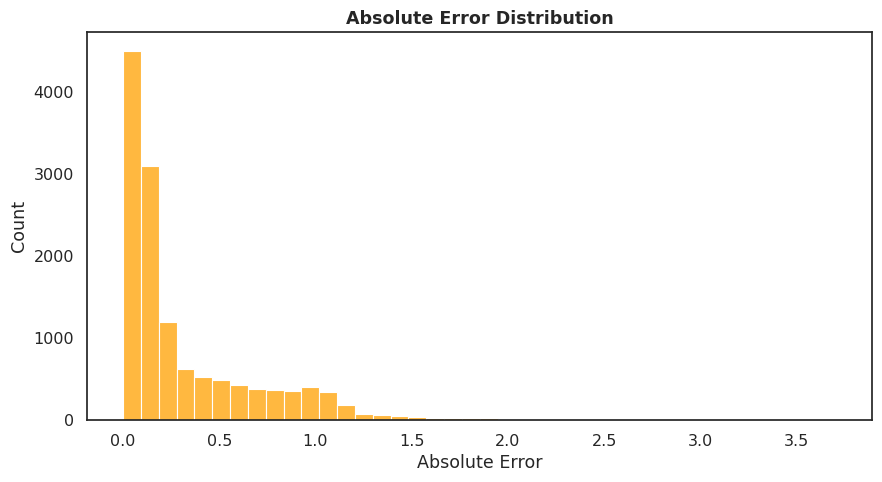

In [12]:
# 전체 절대 오차 분포
sns.set_theme(
    style='white',
    context='notebook',
    font_scale=1.05,
    rc={
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
        'savefig.facecolor': 'white'
    }
)

plt.figure(figsize=(9, 5))

sns.histplot(
    data=prediction_df,
    x='absolute_error',
    bins=40,
    color='#FFA000',
    edgecolor='white',
    linewidth=0.8
)

plt.title('Absolute Error Distribution', fontweight='bold')
plt.xlabel('Absolute Error')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


대부분의 예측은 작은 오차에 모여 있지만, 일부 사례에서는 1점 이상의 큰 오차가 나타납니다.


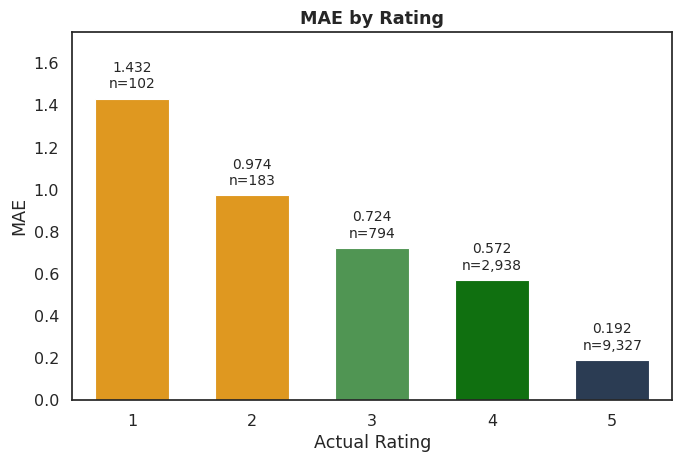

In [13]:
# 실제 평점별 MAE
sns.set_theme(style='white', context='notebook', font_scale=1.05)

rating_plot = rating_error.reset_index()
rating_plot['rating'] = rating_plot['rating'].astype(str)

# 1점과 2점은 같은 다홍색, 3점부터는 안정적인 색상 사용
rating_colors = {
    '1': '#FFA000',
    '2': '#FFA000',
    '3': '#45A049',
    '4': '#008000',
    '5': '#243B5A'
}

plt.figure(figsize=(7, 4.8), facecolor='white')

ax = sns.barplot(
    data=rating_plot,
    x='rating',
    y='mae',
    hue='rating',
    palette=rating_colors,
    legend=False,
    width=0.62,
    edgecolor='white',
    linewidth=0.8
)

ax.set_title('MAE by Rating', fontweight='bold')
ax.set_xlabel('Actual Rating')
ax.set_ylabel('MAE')
ax.set_ylim(0, rating_plot['mae'].max() * 1.22)

for index, row in rating_plot.iterrows():
    ax.text(
        index,
        row['mae'] + 0.035,
        f"{row['mae']:.3f}\nn={int(row['count']):,}",
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()


1·2점은 사례 수가 적고 MAE가 높아, 낮은 평점에서 성능 저하가 두드러집니다.


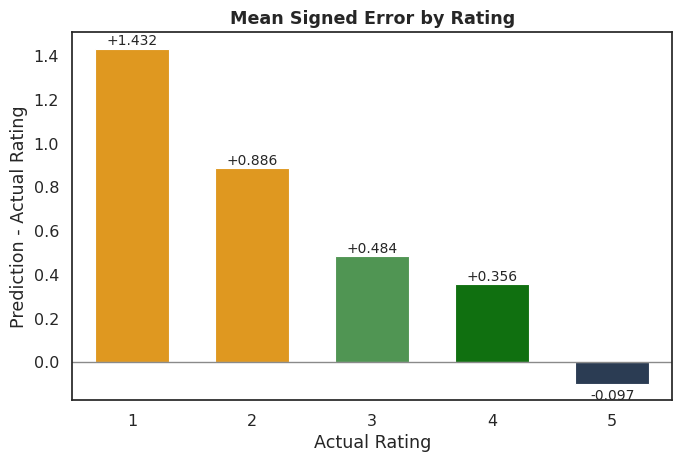

In [14]:
# 실제 평점별 평균 Signed Error
sns.set_theme(style='white', context='notebook', font_scale=1.05)

signed_error_plot = rating_error.reset_index()
signed_error_plot['rating'] = signed_error_plot['rating'].astype(str)

rating_colors = {
    '1': '#FFA000',
    '2': '#FFA000',
    '3': '#45A049',
    '4': '#008000',
    '5': '#243B5A'
}

plt.figure(figsize=(7, 4.8), facecolor='white')

ax = sns.barplot(
    data=signed_error_plot,
    x='rating',
    y='mean_signed_error',
    hue='rating',
    palette=rating_colors,
    legend=False,
    width=0.62,
    edgecolor='white',
    linewidth=0.8
)

ax.axhline(0, color='#8A8A8A', linewidth=1)
ax.set_title('Mean Signed Error by Rating', fontweight='bold')
ax.set_xlabel('Actual Rating')
ax.set_ylabel('Prediction - Actual Rating')

for index, row in signed_error_plot.iterrows():
    value = row['mean_signed_error']
    offset = 0.035 if value >= 0 else -0.055
    ax.text(
        index,
        value + offset,
        f'{value:+.3f}',
        ha='center',
        va='center',
        fontsize=10
    )

plt.tight_layout()
plt.show()


1·2점의 Signed Error가 큰 양수이므로, 모델이 낮은 평점을 실제보다 높게 예측하는 편향이 확인됩니다.


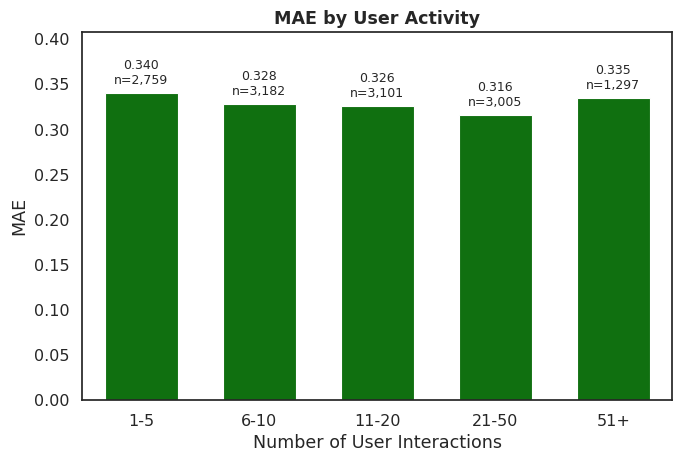

In [15]:
# 사용자 활동량별 MAE
sns.set_theme(style='white', context='notebook', font_scale=1.05)

user_plot = user_error.reset_index()
user_plot['user_group'] = user_plot['user_group'].astype(str)

plt.figure(figsize=(7, 4.8), facecolor='white')

ax = sns.barplot(
    data=user_plot,
    x='user_group',
    y='mae',
    color='#008000',
    width=0.62,
    edgecolor='white',
    linewidth=0.8
)

ax.set_title('MAE by User Activity', fontweight='bold')
ax.set_xlabel('Number of User Interactions')
ax.set_ylabel('MAE')
ax.set_ylim(0, user_plot['mae'].max() * 1.20)

for index, row in user_plot.iterrows():
    ax.text(
        index,
        row['mae'] + 0.007,
        f"{row['mae']:.3f}\nn={int(row['count']):,}",
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()


사용자 활동량별 MAE 차이가 크지 않아, 각 사용자가 구매한 제품 수 기반으로 전체 오류를 설명하기는 어렵습니다.


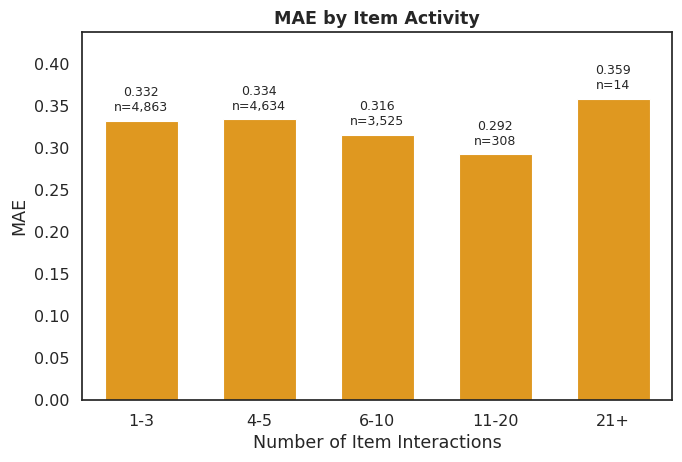

In [16]:
# 상품 활동량별 MAE
sns.set_theme(style='white', context='notebook', font_scale=1.05)

item_plot = item_error.reset_index()
item_plot['item_group'] = item_plot['item_group'].astype(str)

plt.figure(figsize=(7, 4.8), facecolor='white')

ax = sns.barplot(
    data=item_plot,
    x='item_group',
    y='mae',
    color='#FFA000',
    width=0.62,
    edgecolor='white',
    linewidth=0.8
)

ax.set_title('MAE by Item Activity', fontweight='bold')
ax.set_xlabel('Number of Item Interactions')
ax.set_ylabel('MAE')
ax.set_ylim(0, item_plot['mae'].max() * 1.22)

for index, row in item_plot.iterrows():
    ax.text(
        index,
        row['mae'] + 0.008,
        f"{row['mae']:.3f}\nn={int(row['count']):,}",
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()


상품 상호작용 1~10건 구간의 MAE는 비슷하며, 21건 이상 구간은 표본이 14건뿐이므로 해석에 주의해야 합니다.


## 정리

평점 불균형과 높은 평점 중심의 예측 편향이 우선 확인되며, 큰 오류 사례는 텍스트 요약의 속성 누락과 감성 변화를 추가로 살펴볼 필요가 있습니다.


## 다음 분석

05 텍스트 오류 분석에서는 원본 리뷰와 LLaMA 요약문을 연결해 속성 보존, 부정 속성 누락, 감성 반전, 요약문 단독 속성을 확인합니다.
LLaVA와 Attention Rollout은 분석 목적이 다르므로 기존 별도 노트북에서 확인합니다.
